# Order facts and business overview

The raw schema spreads one order across five tables. `sql/order_facts.sql` flattens it into one row per
order using CTEs and window functions:
- **CTEs** aggregate items, payments, and reviews to the order level.
- **`ROW_NUMBER()`** picks each order's main item (for its category) and its latest review, and numbers
  each customer's orders in time (`order_number`).
- **`COUNT(*) OVER (PARTITION BY ...)`** gives every order its customer's lifetime order count.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SQL = ROOT / "sql"
IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

load_dotenv(ROOT / ".env")
engine = create_engine(os.environ["DATABASE_URL"])


def run_sql(name):
    return pd.read_sql((SQL / f"{name}.sql").read_text(), engine)


with engine.begin() as conn:
    conn.execute(text((SQL / "order_facts.sql").read_text()))

pd.read_sql("SELECT * FROM order_facts LIMIT 3", engine).T

,0,1,2
order_id,e22acc9c116caa3f2b7121bbb380d08e,3594e05a005ac4d06a72673270ef9ec9,b33ec3b699337181488304f362a6b734
customer_unique_id,0000366f3b9a7992bf8c76cfdf3221e2,0000b849f77a49e4a4ce2b2a4ca5be3f,0000f46a3911fa3c0805444483337064
customer_state,SP,SP,SC
order_status,delivered,delivered,delivered
purchased_at,2018-05-10 10:56:27,2018-05-07 11:11:27,2017-03-10 21:05:03
purchase_month,2018-05-01,2018-05-01,2017-03-01
delivered_at,2018-05-16 20:48:37,2018-05-10 18:02:42,2017-04-05 14:38:47
estimated_at,2018-05-21 00:00:00,2018-05-15 00:00:00,2017-04-07 00:00:00
items,1,1,1
item_value,129.9,18.9,69.0


In [2]:
pd.read_sql("""
SELECT
    (SELECT COUNT(*) FROM order_facts) AS order_facts_rows,
    (SELECT COUNT(*) FROM orders) AS orders_rows,
    (SELECT SUM(item_value) FROM order_facts) AS item_value_in_facts,
    (SELECT SUM(price) FROM order_items) AS item_value_in_items,
    (SELECT COUNT(*) FROM order_facts WHERE order_number = 1) AS first_orders,
    (SELECT COUNT(DISTINCT customer_unique_id) FROM customers) AS unique_customers
""", engine).T.rename(columns={0: "value"})

,value
order_facts_rows,99441.0
orders_rows,99441.0
item_value_in_facts,13591643.7
item_value_in_items,13591643.7
first_orders,96096.0
unique_customers,96096.0


The table has exactly one row per order, item totals reconcile to the cent, and there is exactly one
"first order" per real customer.

In [3]:
monthly = run_sql("monthly_kpis")
monthly

,purchase_month,orders,revenue,avg_order_value,customers,returning_pct,late_pct,avg_review,revenue_growth_pct
0,2017-01-01,787,137007.0,174.09,753,3.45,2.8,4.09,NaN
1,2017-02-01,1718,283622.0,165.09,1693,1.48,2.9,4.10,107.0
2,2017-03-01,2617,425656.0,162.65,2577,1.75,4.4,4.13,50.1
3,2017-04-01,2377,405988.0,170.80,2345,2.00,6.4,4.07,-4.6
4,2017-05-01,3640,582926.0,160.14,3569,2.77,2.9,4.18,43.6
5,2017-06-01,3205,499827.0,155.95,3142,3.21,3.0,4.18,-14.3
6,2017-07-01,3946,578859.0,146.70,3872,3.18,2.7,4.23,15.8
7,2017-08-01,4272,662072.0,154.98,4191,3.27,2.9,4.27,14.4
8,2017-09-01,4227,717195.0,169.67,4154,3.59,4.3,4.22,8.3
9,2017-10-01,4547,764785.0,168.20,4481,3.39,4.1,4.17,6.6


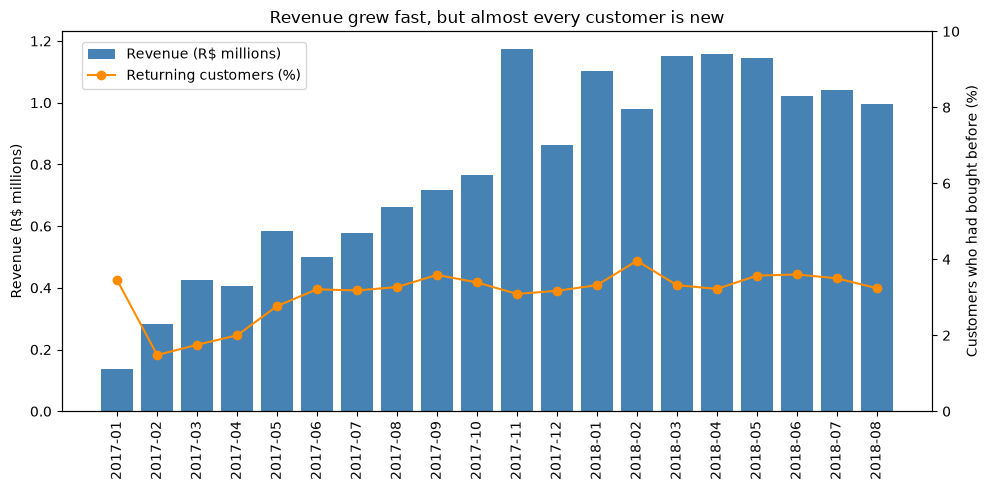

In [4]:
fig, ax1 = plt.subplots(figsize=(10, 5))
months = monthly["purchase_month"].astype(str).str[:7]
ax1.bar(months, monthly["revenue"] / 1e6, color="steelblue", label="Revenue (R$ millions)")
ax1.set_ylabel("Revenue (R$ millions)")
ax1.tick_params(axis="x", rotation=90)
ax2 = ax1.twinx()
ax2.plot(months, monthly["returning_pct"], color="darkorange", marker="o", label="Returning customers (%)")
ax2.set_ylabel("Customers who had bought before (%)")
ax2.set_ylim(0, 10)
ax1.set_title("Revenue grew fast, but almost every customer is new")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.92))
plt.tight_layout()
plt.savefig(IMAGES / "monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
pd.read_sql("""
SELECT
    category,
    COUNT(*) AS orders,
    ROUND(SUM(payment_value), 0) AS revenue,
    ROUND(SUM(payment_value) * 100.0 / SUM(SUM(payment_value)) OVER (), 1) AS revenue_share_pct,
    ROUND(AVG(review_score), 2) AS avg_review
FROM order_facts
WHERE order_status = 'delivered'
GROUP BY category
ORDER BY revenue DESC
LIMIT 10
""", engine)

,category,orders,revenue,revenue_share_pct,avg_review
0,health_beauty,8613,1412849.0,9.2,4.23
1,watches_gifts,5478,1265742.0,8.2,4.12
2,bed_bath_table,9184,1226963.0,8.0,4.01
3,sports_leisure,7493,1117793.0,7.2,4.24
4,computers_accessories,6512,1032850.0,6.7,4.08
5,furniture_decor,6188,877141.0,5.7,4.08
6,housewares,5680,757979.0,4.9,4.20
7,cool_stuff,3530,692225.0,4.5,4.23
8,auto,3793,669827.0,4.3,4.15
9,garden_tools,3400,563392.0,3.7,4.20


In [6]:
pd.read_sql("""
SELECT
    customer_orders AS orders_per_customer,
    COUNT(DISTINCT customer_unique_id) AS customers,
    ROUND(COUNT(DISTINCT customer_unique_id) * 100.0
          / SUM(COUNT(DISTINCT customer_unique_id)) OVER (), 2) AS pct_of_customers
FROM order_facts
GROUP BY customer_orders
ORDER BY customer_orders
""", engine)

,orders_per_customer,customers,pct_of_customers
0,1,93099,96.88
1,2,2745,2.86
2,3,203,0.21
3,4,30,0.03
4,5,8,0.01
5,6,6,0.01
6,7,3,0.00
7,9,1,0.00
8,17,1,0.00


### Findings
- `order_facts` has exactly one row per order (99,441), item totals reconcile to the cent with
  `order_items`, and there is exactly one first order for each of the 96,096 customers.
- **Revenue grew about 8x**, from R\$137k in January 2017 to R\$1.0-1.2M a month in 2018, but **only about
  3% of each month's customers had bought before**. Growth came entirely from new customers.
- **96.9% of customers ordered exactly once.** Only 2.9% ordered twice, and 0.3% three or more times.
- Late deliveries spiked in November 2017 (Black Friday, 12.2% late) and February-March 2018 (14.0% and
  18.5%), and the average review dropped in exactly those months (3.95, 3.86, 3.76). Notebook 04 digs into
  that link.
- Health & beauty, watches & gifts, and bed/bath/table lead revenue. The top 10 categories bring 62%.